In [1]:
import numpy as np
from pathlib import Path
import os, sys
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import warnings
import pandas as pd
import json

repo_root = Path("/home/thardy/elefanto/ConsciousnessTeam_Data/SOUNDMODEL/Data_SoundGOOD/LEAD_ExperimentalFolder")
os.chdir(repo_root)

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
os.environ["PYTHONPATH"] = str(repo_root) + os.pathsep + os.environ.get("PYTHONPATH", "")

import LEAD as lead


# Important variables
cwd = Path.cwd()
SNRs = np.array([-np.inf,-13,-11,-9,-7,-5,-3])
SubIDs = ['01','02','03','05','06','07','08','09','11','12','13','14','15','17','19','20','22','23','24','25']
colormap = {0: (0, 0, 0), 1: (0, 0.25, 1), 2: (0, 0.9375, 1), 3: (0, 0.91, 0.1), 4: (1, 0.6, 0), 5: (1, 0, 0), 6: (0.8, 0, 0)}

In [2]:
def count_sign_changes(delta_x):
    signs = np.sign(delta_x)
    sign_changes = np.sum(np.diff(signs) != 0)
    return sign_changes

def is_bifurcation(delta_x_list):
    counts = [count_sign_changes(delta_x) for delta_x in delta_x_list]
    unique_counts = set(counts)
    return len(unique_counts) > 1

def metastability_score(f, df, x_grid, tau):
    distance_to_critical = f(x_grid)**2 + df(x_grid)**2
    normalized_distance = distance_to_critical * tau**2 # between 0 (critical) and 1 (linear dynamics)
    return 1-np.min(normalized_distance) 

In [3]:
json_path = cwd / "5CV_Passive_early.json"
with open(json_path, "r") as f:
    data_5cv = json.load(f)
    results_cv = data_5cv.get("results_cv")
    print("Loaded results_cv:", results_cv)

Loaded results_cv: ['NonLinear1', 'NonLinear1', 'NonLinear1', 'Linear', 'NonLinear1', 'NonLinear1', 'Linear', 'NonLinear1', 'Linear', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'GainModulation', 'GainModulation', 'NonLinear1', 'GainModulation', 'NonLinear1', 'GainModulation', 'NonLinear1']


# Bifurcation Probability & Metastability Scoring 

### Via Particle Density Estimation for the best model **per participant**

Found existing summary at Fit_Passive_early/MetaBifurc_AllModels_21^2/metabifurc.csv. Loading progress...
{0: 0.0, 1: 0.0, 2: 0.0, 3: 0.0}
{0: 0.0170892944748578, 1: 0.6314408418213657, 2: 0.1820086253329279, 3: 0.0}
Loaded results_cv: ['NonLinear1', 'NonLinear1', 'NonLinear1', 'Linear', 'NonLinear1', 'NonLinear1', 'Linear', 'NonLinear1', 'Linear', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'GainModulation', 'GainModulation', 'NonLinear1', 'GainModulation', 'NonLinear1', 'GainModulation', 'NonLinear1']
part 0 lets go, best model is NonLinear1
>>> Part 0 already exists in CSV. Skipping...
part 1 lets go, best model is NonLinear1
>>> Part 1 already exists in CSV. Skipping...
part 2 lets go, best model is NonLinear1
>>> Part 2 already exists in CSV. Skipping...
part 3 lets go, best model is Linear
>>> Part 3 already exists in CSV. Skipping...
part 4 lets go, best model is NonLinear1
Max threshold: 1.46


Grid Search for Part 4:   0%|          | 0/21 [00:00<?, ?it/s]

Part 4 has a 0.0000 probability of bifurcation.
Part 4 has a 0.8245 metastability score.
part 5 lets go, best model is NonLinear1
Max threshold: 1.14


Grid Search for Part 5:   0%|          | 0/21 [00:00<?, ?it/s]

Part 5 has a 0.0000 probability of bifurcation.
Part 5 has a 0.0000 metastability score.
part 6 lets go, best model is Linear
Max threshold: 1.22
Part 6 has a 0.0000 probability of bifurcation.
Part 6 has a 0.0000 metastability score.
part 7 lets go, best model is NonLinear1
Max threshold: 1.23


Grid Search for Part 7:   0%|          | 0/21 [00:00<?, ?it/s]

... (6 outputs left out)

Part 11 has a 0.0000 probability of bifurcation.
Part 11 has a 0.7225 metastability score.
part 12 lets go, best model is NonLinear1
Max threshold: 1.27


Grid Search for Part 12:   0%|          | 0/21 [00:00<?, ?it/s]

Part 12 has a 0.0000 probability of bifurcation.
Part 12 has a 0.2960 metastability score.
part 13 lets go, best model is GainModulation
Max threshold: 1.42
Fitted threshold from parent model: 0.50


Tau grid for part 13:   0%|          | 0/21 [00:00<?, ?it/s]

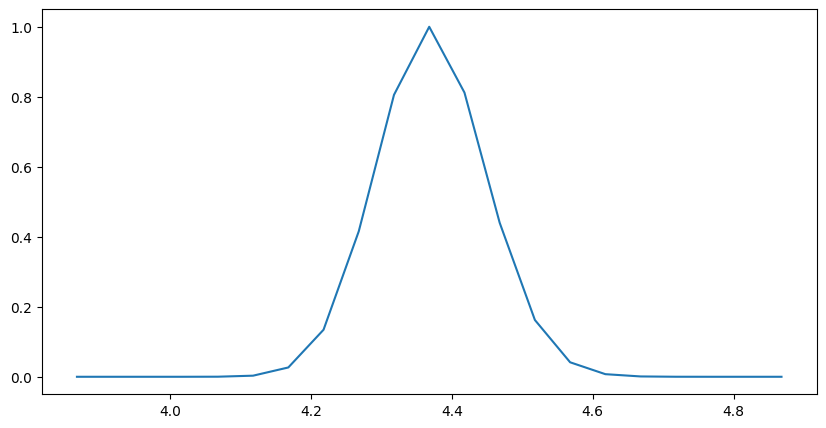

2D Search (Tau) for Part 13: 0it [00:00, ?it/s]

4.117973762657815 is a good enough tau
4.167973762657815 is a good enough tau
4.217973762657815 is a good enough tau
4.267973762657816 is a good enough tau
4.317973762657815 is a good enough tau
4.367973762657815 is a good enough tau
4.417973762657815 is a good enough tau
4.467973762657815 is a good enough tau
4.517973762657816 is a good enough tau
4.567973762657815 is a good enough tau
4.617973762657815 is a good enough tau
Part 13 has a 0.2634 probability of bifurcation.
Part 13 has a 0.9856 metastability score.
part 14 lets go, best model is GainModulation
Max threshold: 1.31
Fitted threshold from parent model: 0.48


Tau grid for part 14:   0%|          | 0/21 [00:00<?, ?it/s]

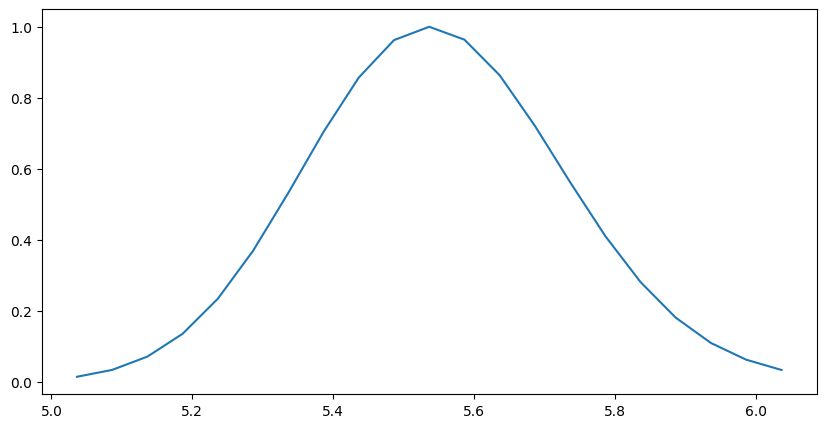

2D Search (Tau) for Part 14: 0it [00:00, ?it/s]

5.03622300878297 is a good enough tau
5.086223008782969 is a good enough tau
5.136223008782969 is a good enough tau
5.18622300878297 is a good enough tau
5.23622300878297 is a good enough tau
5.28622300878297 is a good enough tau
5.336223008782969 is a good enough tau
5.386223008782969 is a good enough tau
5.43622300878297 is a good enough tau
5.48622300878297 is a good enough tau
5.53622300878297 is a good enough tau
5.586223008782969 is a good enough tau
5.63622300878297 is a good enough tau
5.68622300878297 is a good enough tau
5.73622300878297 is a good enough tau
5.78622300878297 is a good enough tau
5.836223008782969 is a good enough tau
5.88622300878297 is a good enough tau
5.93622300878297 is a good enough tau
5.98622300878297 is a good enough tau
6.03622300878297 is a good enough tau
Part 14 has a 0.0000 probability of bifurcation.
Part 14 has a 0.9326 metastability score.
part 15 lets go, best model is NonLinear1
Max threshold: 1.33


Grid Search for Part 15:   0%|          | 0/21 [00:00<?, ?it/s]

Part 15 has a 0.0000 probability of bifurcation.
Part 15 has a 0.0110 metastability score.
part 16 lets go, best model is GainModulation
Max threshold: 1.28
Fitted threshold from parent model: 0.33


Tau grid for part 16:   0%|          | 0/21 [00:00<?, ?it/s]

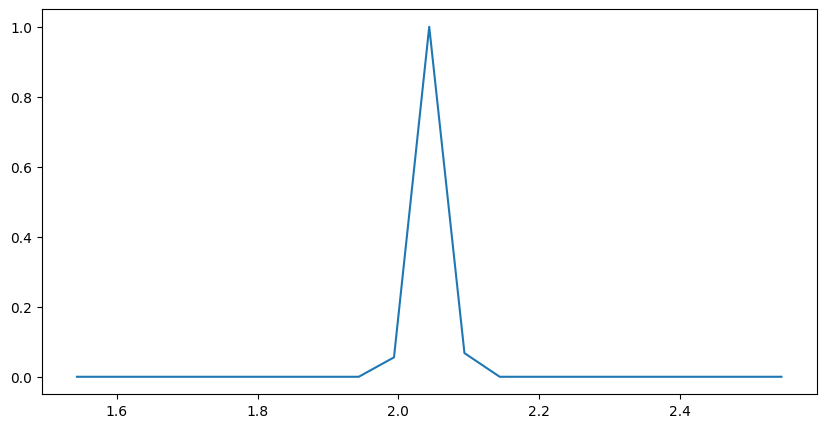

2D Search (Tau) for Part 16: 0it [00:00, ?it/s]

1.9937100845305797 is a good enough tau
2.04371008453058 is a good enough tau
2.0937100845305796 is a good enough tau
Part 16 has a 0.0000 probability of bifurcation.
Part 16 has a 0.8520 metastability score.
part 17 lets go, best model is NonLinear1
Max threshold: 1.25


Grid Search for Part 17:   0%|          | 0/21 [00:00<?, ?it/s]

Part 17 has a 0.0000 probability of bifurcation.
Part 17 has a 0.0182 metastability score.
part 18 lets go, best model is GainModulation
Max threshold: 1.44
Fitted threshold from parent model: 0.42


Tau grid for part 18:   0%|          | 0/21 [00:00<?, ?it/s]

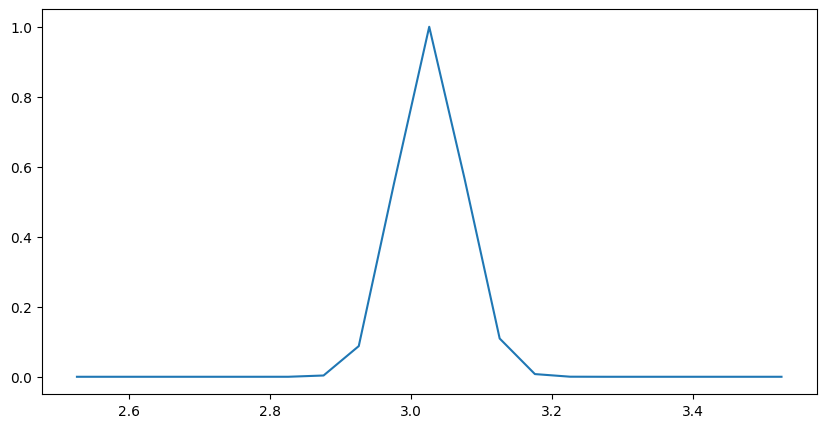

2D Search (Tau) for Part 18: 0it [00:00, ?it/s]

2.8756264111936756 is a good enough tau
2.9256264111936754 is a good enough tau
2.9756264111936757 is a good enough tau
3.0256264111936755 is a good enough tau
3.0756264111936753 is a good enough tau
3.1256264111936756 is a good enough tau
3.1756264111936754 is a good enough tau
Part 18 has a 0.0000 probability of bifurcation.
Part 18 has a 0.9020 metastability score.
part 19 lets go, best model is NonLinear1
Max threshold: 1.38


Grid Search for Part 19:   0%|          | 0/21 [00:00<?, ?it/s]

Part 19 has a 0.0000 probability of bifurcation.
Part 19 has a 0.4498 metastability score.


In [13]:
task = "Passive"
period = "early"
file_path = Path(f'Fit_{task}_{period}')
sub_file_path = "MetaBifurc_AllModels_21^2"

# Define the summary path clearly and load existing progress 
summary_path = file_path / sub_file_path / "metabifurc.csv"
if summary_path.exists():
    print(f"Found existing summary at {summary_path}. Loading progress...")
    existing_df = pd.read_csv(summary_path, index_col=0)
    bifurcation_prob = existing_df["probability_of_bifurcation"].to_dict()
    metastability_scores = existing_df["metastability_score"].to_dict()
    print(bifurcation_prob)
    print(metastability_scores)
else:
    bifurcation_prob, metastability_scores = {}, {}

# load the name of the best model for each participant
json_path = cwd / f"5CV_{task}_{period}.json"
with open(json_path, "r") as f:
    data_5cv = json.load(f)
    results_cv = data_5cv.get("results_cv")
    print("Loaded results_cv:", results_cv)

    
for part in range(20):
    best_model = results_cv[part]
    print(f'part {part} lets go, best model is {best_model}')

    # --- SKIP if already processed --- 
    if part in bifurcation_prob:
        print(f">>> Part {part} already exists in CSV. Skipping...")
        continue
    
    # --- Load Data ---
    data_ref = f'myEpochs_{task}/Epoch_{SubIDs[part]}-epo.fif'
    epochs_file = cwd.parents[0] / data_ref
    
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        state_train = lead.STG(epochs_file, tmin=100, tmax=200)
        n_categories = len(list(state_train.keys()))
        categories = list(range(n_categories))

    # --- Input Definition ---
    one_input = np.concatenate((np.zeros(60), np.ones(10), np.zeros(180)))
    input_train = {cat: np.stack([one_input for _ in range(state_train[cat].shape[0])]) for cat in categories}

    # --- Data Reformating ---
    state_train_constant_stim = {cat: state_train[cat][:,60:70] for cat in range(1, n_categories)}
    input_train_constant_stim = {cat: input_train[cat][:,60:70] for cat in range(1, n_categories)}
    no_stim_sliced = np.concatenate([state_train[0][:, i*50:(i+1)*50] for i in range(5)])
    pre_stim_sliced = np.concatenate([state_train[cat][:, :50] for cat in range(1, n_categories)])
    state_train_constant_stim[0] = np.concatenate((no_stim_sliced, pre_stim_sliced))
    input_train_constant_stim[0] = np.zeros_like(state_train_constant_stim[0])

    # --- Define upper bound for threshold parameter ---
    max_threshold = np.percentile(state_train[n_categories-1], 90)
    print(f"Max threshold: {max_threshold:.2f}")


    if best_model == 'GainModulation':

        # --- Load Parent Parameters ---
        gainmodul_parent = lead.model.StratifiedGainModulation(
            tau=10, process_noise=0.1, measure_noise=0.1, threshold=1, sharpness=5)
        param_path = file_path / f"GainModulatedModel_part{part}_params"
        gainmodul_parent.load_params(param_path)
        print(f"Fitted threshold from parent model: {gainmodul_parent.threshold:.2f}")


        # --- Define Ranges ---
        thresh_range = np.linspace(0, 2, 21)
        if gainmodul_parent.tau < 2:
            tau_range = np.linspace(1.5, 2.5, 21)
        else:
            tau_range = np.linspace(gainmodul_parent.tau - 0.5, gainmodul_parent.tau + 0.5, 21)

        
        # --- Step 1: Grid Search for Tau (to fix input params for the next step) ---
        
        ll_list_tau, params_through_tau = [], []
        for tau in tqdm(tau_range, desc=f"Tau grid for part {part}"):
            linear_resting_state = lead.model.StratifiedLinear(tau=tau, process_noise=0.1, measure_noise=0.1, w0=0)
            
            linear_resting_state.fit(
                state_series={0: state_train_constant_stim[0]},
                input_series={0: input_train_constant_stim[0]},
                init_params=[tau, 0.1, 0.1] + [0]*7,
                bounds=[(1, 25), (0.01, 1), (0.01, 1)] + [(0, 1)]*7,
                fixed_params=['tau'] + [f'w{i}' for i in range(7)])
            
            ll_list_tau.append(linear_resting_state.loglikelihood({0: state_train_constant_stim[0]}, {0: input_train_constant_stim[0]}))
            params_through_tau.append([linear_resting_state.tau, linear_resting_state.process_noise, linear_resting_state.measure_noise])

        # Plot the distrib for visual check
        ll_array_tau = np.array(ll_list_tau)
        likelihood_tau = np.exp(ll_array_tau - np.max(ll_array_tau))
        plt.figure(figsize=(10,5))
        plt.plot(tau_range, likelihood_tau)
        plt.show()


        # --- Step 2: 2D Grid Search (Tau vs Threshold) ---
        bif_array, meta_array = np.zeros((len(tau_range), len(thresh_range))), np.zeros((len(tau_range), len(thresh_range)))
        ll_array = -np.inf*np.ones((len(tau_range), len(thresh_range)))

        # We iterate through the params found in Step 1
        for idx_tau, [tau, process_noise, measure_noise] in tqdm(enumerate(params_through_tau), desc=f"2D Search (Tau) for Part {part}"):

            # When tau is too unlikely, keep the default ll = -np.inf and bif = meta = 0 (no bifurcation)
            if likelihood_tau[idx_tau] < 0.001:
                continue
            print(f'{tau} is a good enough tau')

            ll_this_tau = ll_list_tau[idx_tau]

            # Inner loop over threshold
            for idx_th, threshold in enumerate(thresh_range):

                # When threshold is too high compared to data, keep the default ll = -np.inf and bif = meta = 0
                if threshold > max_threshold:
                    continue
                
                # A. Fit gain and input_weight for this specific (tau, threshold) combo
                ll_local = 0
                # Initialize base model for this grid point
                gainmodul = lead.model.StratifiedGainModulation(
                    tau=tau, process_noise=process_noise, measure_noise=measure_noise, 
                    threshold=threshold, sharpness=5)
                
                for cat in range(1, n_categories):
                    # Retrieve parent weights
                    w_parent = getattr(gainmodul_parent, f'w{cat}')
                    g_parent = getattr(gainmodul_parent, f'g{cat}')
                    
                    gainmodul_one_cat = lead.model.GainModulation(
                        tau=tau, process_noise=process_noise, measure_noise=measure_noise, 
                        threshold=threshold, sharpness=5, 
                        input_weight=w_parent, gain=g_parent)
                    
                    # Fit specific category
                    gainmodul_one_cat.fit(
                        state_series={0: state_train_constant_stim[cat]},
                        input_series={0: input_train_constant_stim[cat]},
                        init_params=[getattr(gainmodul_one_cat, pname) for pname in gainmodul_one_cat._param_names],
                        bounds=[(1,25), (0.01, 1), (0.01, 1), (0, 1), (0, 1), (0, 2), (0, 10)],
                        fixed_params=['tau', 'process_noise', 'measure_noise', 'threshold', 'sharpness'])
                    
                    ll_local += gainmodul_one_cat.loglikelihood({0: state_train_constant_stim[cat]}, {0: input_train_constant_stim[cat]})
                    
                    # Update the main stratified model with fitted params
                    gainmodul.set_params({f'w{cat}': gainmodul_one_cat.input_weight, f'g{cat}': gainmodul_one_cat.gain})
                
                ll_array[idx_tau, idx_th] = ll_this_tau + ll_local
                
                # B. Assess bifurcation and metastability (Linear Interpolation)
                states = np.linspace(-0.5, 3, 1000)
                delta_x_list = []
                max_metascore = 0
                
                for cat in range(n_categories - 1):
                    # Initial state diff
                    delta_x_list.append(gainmodul.core(state=states, input_value=1, signal_category=cat) - states)
                    
                    w1, g1 = getattr(gainmodul, f'w{cat}'), getattr(gainmodul, f'g{cat}')
                    w2, g2 = getattr(gainmodul, f'w{cat+1}'), getattr(gainmodul, f'g{cat+1}')
                    
                    # Travel on the (w1, g1) -> (w2, g2) segment 
                    for t in np.linspace(0, 1, 100):
                        w, g = w1 + t*(w2-w1), g1 + t*(g2-g1)
                        
                        interp_model = lead.model.GainModulation(
                            tau=tau, process_noise=process_noise, measure_noise=measure_noise, 
                            threshold=threshold, sharpness=5, 
                            input_weight=w, gain=g
                        )

                        # Prepare for metastability score calculation
                        model_func = interp_model.core
                        def f(states, input_value=0, signal_category=cat):
                            return model_func(states, input_value * np.ones_like(states), signal_category) - states
                        def df(states, input_value=0, signal_category=cat):
                            epsilon = 1e-5
                            return (f(states + epsilon, input_value, signal_category) - f(states - epsilon, input_value, signal_category)) / (2*epsilon)
            
                        # Compute metastability score
                        metascore = metastability_score(lambda x: f(x, input_value=1, signal_category=cat), 
                                                        lambda x: df(x, input_value=1, signal_category=cat), 
                                                        states, tau=tau)
                        max_metascore = max(max_metascore, metascore)

                        # Prepare for bifurcation check
                        delta_x_list.append(interp_model.core(state=states, input_value=1, signal_category=0) - states)

                # Compute bifurcation check
                bifbool = is_bifurcation(delta_x_list)
                bif_array[idx_tau, idx_th] = int(bifbool)
                meta_array[idx_tau, idx_th] = max_metascore

    if best_model == 'NonLinear1':

        # --- Load Parent Parameters ---
        gainfixed_parent = lead.model.StratifiedNonLinear1(
            tau=10, process_noise=0.1, measure_noise=0.1, threshold=1, sharpness=5, gain=0)
        param_path = file_path / f"GainFixedModel_part{part}_params"
        gainfixed_parent.load_params(param_path)

        # --- Define Ranges ---
        thresh_range = np.linspace(0, 2, 21)
        if gainfixed_parent.tau < 2:
            tau_range = np.linspace(1.5, 2.5, 21)
        else:
            tau_range = np.linspace(gainfixed_parent.tau - 0.5, gainfixed_parent.tau + 0.5, 21)

        # --- Grid Search for Tau & threshold at the same time (model StratifiedNonLinear1) ---
        bif_array, meta_array = np.zeros((len(tau_range), len(thresh_range))), np.zeros((len(tau_range), len(thresh_range)))
        ll_array = -np.inf*np.ones((len(tau_range), len(thresh_range)))

        for idx_tau, tau in tqdm(enumerate(tau_range), total=len(tau_range), desc=f"Grid Search for Part {part}"):
            for idx_th, threshold in enumerate(thresh_range):

                # When threshold is too high compared to data, keep the default ll = -np.inf and bif = meta = 0
                if threshold > max_threshold:
                    continue

                # --- Define Model Instance ---
                gainfixed = lead.model.StratifiedNonLinear1(
                    tau=tau, 
                    process_noise=gainfixed_parent.process_noise, 
                    measure_noise=gainfixed_parent.measure_noise, 
                    threshold=threshold, 
                    gain=gainfixed_parent.gain,
                    sharpness=5
                )
                gainfixed.set_params({f'w{cat}': getattr(gainfixed_parent, f'w{cat}') for cat in range(1, n_categories)})

                # A. Fit Relevant Parameters (strategy like lead.fitting_tools)
                for k_loop in range(2):
                    
                    # refine gain first
                    gainfixed.fit(
                        state_series=state_train_constant_stim,
                        input_series=input_train_constant_stim,
                        init_params=[getattr(gainfixed, pname) for pname in gainfixed._param_names],
                        bounds=[(1,25), (0.01, 1), (0.01, 1)] + [(0, 1)]*7 + [(0, 0.5), (0, 2), (0, 10)],
                        fixed_params=['tau', 'process_noise', 'measure_noise', 'threshold', 'sharpness'] + [f'w{cat}' for cat in range(1, n_categories)])
                    
                    # refine the input weights
                    for cat in range(1, n_categories):
                        
                        gainfixed_one_cat = lead.model.NonLinear1(
                            tau=gainfixed.tau, 
                            process_noise=gainfixed.process_noise, 
                            measure_noise=gainfixed.measure_noise,
                            input_weight=getattr(gainfixed, f'w{cat}'),
                            gain=gainfixed.gain,
                            threshold=gainfixed.threshold, 
                            sharpness=5
                        )
                        
                        gainfixed_one_cat.fit(
                            state_series={0: state_train_constant_stim[cat]},
                            input_series={0: input_train_constant_stim[cat]},
                            init_params=[getattr(gainfixed_one_cat, pname) for pname in gainfixed_one_cat._param_names],
                            bounds=[(1,25), (0.01, 1), (0.01, 1), (0, 1), (0, 1), (0, 2), (0, 10)],
                            fixed_params=['tau', 'process_noise', 'measure_noise', 'threshold', 'gain', 'sharpness'],
                            feedback=False
                        )
                        gainfixed.set_params({f'w{cat}': gainfixed_one_cat.input_weight})

                ll_array[idx_tau, idx_th] = gainfixed.loglikelihood(state_train_constant_stim, input_train_constant_stim)


                # B. Assess bifurcation and metastability (Linear Interpolation)
                states = np.linspace(-0.5, 3, 1000)
                delta_x_list = []
                max_metascore = 0
                
                for cat in range(n_categories - 1):
                    # Initial state diff
                    delta_x_list.append(gainfixed.core(state=states, input_value=1, signal_category=cat) - states)
                    
                    w1, w2 = getattr(gainfixed, f'w{cat}'), getattr(gainfixed, f'w{cat+1}')
                    
                    # Travel on the w1 -> w2 segment
                    for t in np.linspace(0, 1, 100):
                        w = w1 + t*(w2-w1)
                        
                        interp_model = lead.model.NonLinear1(
                            tau=gainfixed.tau, 
                            process_noise=gainfixed.process_noise, 
                            measure_noise=gainfixed.measure_noise, 
                            threshold=gainfixed.threshold, 
                            sharpness=gainfixed.sharpness, 
                            input_weight=w, 
                            gain=gainfixed.gain
                        )
                        # Prepare for metastability score calculation
                        model_func = interp_model.core
                        def f(states, input_value=0, signal_category=cat):
                            return model_func(states, input_value * np.ones_like(states), signal_category) - states
                        def df(states, input_value=0, signal_category=cat):
                            epsilon = 1e-5
                            return (f(states + epsilon, input_value, signal_category) - f(states - epsilon, input_value, signal_category)) / (2*epsilon)
            
                        # Compute metastability score
                        metascore = metastability_score(lambda x: f(x, input_value=1, signal_category=cat), 
                                                        lambda x: df(x, input_value=1, signal_category=cat), 
                                                        states, tau=tau)
                        max_metascore = max(max_metascore, metascore)

                        # Prepare for bifurcation check
                        delta_x_list.append(interp_model.core(state=states, input_value=1, signal_category=0) - states)

                # Compute bifurcation check
                bifbool = is_bifurcation(delta_x_list)
                bif_array[idx_tau, idx_th] = int(bifbool)
                meta_array[idx_tau, idx_th] = max_metascore


    if best_model == 'Linear':
        bif_array, meta_array = np.zeros((20, 20)), np.zeros((20, 20))
        ll_array = -np.ones((20, 20))


    # --- Process Results ---
    likelihood = np.exp(ll_array - np.max(ll_array))

    # Save Results
    os.makedirs(file_path / sub_file_path, exist_ok=True)
    np.savez(file_path / sub_file_path / f"2D_grid_search_part{part}.npz", threshold_range=thresh_range, tau_range=tau_range, ll=ll_array, likelihood=likelihood, bifbool=bif_array, metascore=meta_array)

    # Weighting BifProb and MetaScore over the 2D surface)
    bifprob = np.average(bif_array, weights=likelihood)
    metascore = np.average(meta_array, weights=likelihood)
    bifurcation_prob[part], metastability_scores[part] = bifprob, metascore
    print(f'Part {part} has a {bifprob:.4f} probability of bifurcation.')
    print(f'Part {part} has a {metascore:.4f} metastability score.')

    # Save summary CSV
    df_bifprob = pd.DataFrame.from_dict(
        bifurcation_prob, orient="index", columns=["probability_of_bifurcation"]
    ).sort_index()
    df_metascore = pd.DataFrame.from_dict(
        metastability_scores, orient="index", columns=["metastability_score"]
    ).sort_index()
    df = pd.concat([df_bifprob, df_metascore], axis=1)
    df.to_csv(file_path / sub_file_path / "metabifurc.csv")

    # --- 3. Plotting (2D Heatmap with Contours) ---
    plt.figure(figsize=(10, 8))
    
    # Create 2D Meshgrid for plotting
    # thresh_range (x-axis), tau_range (y-axis)
    X, Y = np.meshgrid(thresh_range, tau_range)
    
    # 1. Plot Heatmap of Likelihood
    # Using pcolormesh for the heatmap
    pcm = plt.pcolormesh(X, Y, likelihood, shading='auto', cmap='viridis')
    plt.colorbar(pcm, label='Relative Likelihood')
    
    # 2. Plot Contour of Bifurcation Boundary
    # We draw a line at 0.5 (since bif_array is 0 or 1) to show the border
    # colors='red' makes the bifurcation line distinct
    if np.any(bif_array) and not np.all(bif_array):
        CS = plt.contour(X, Y, bif_array, levels=[0.5], colors='red', linewidths=2)
        # Create a proxy artist for the legend
        from matplotlib.lines import Line2D
        proxy_line = Line2D([0], [0], color='red', linewidth=2, label='Bifurcation Boundary')
        plt.legend(handles=[proxy_line], loc='upper right')
    elif np.all(bif_array):
        plt.title(f"Part {part} (All Bifurcation)")
    else:
        plt.title(f"Part {part} (No Bifurcation)")

    plt.title(f'Parameter Space: Tau vs Threshold - Part {part}\nWeighted Bifurcation Prob: {bifprob:.3f}')
    plt.xlabel('Threshold')
    plt.ylabel('Tau')
    
    # Save plot
    plt.savefig(file_path / sub_file_path / f"2D_likelihood_part{part}_{task}.png")
    plt.close()

### Via Particle Density Estimation for the Modulated Gain model

Loaded results_cv: ['NonLinear1', 'NonLinear1', 'NonLinear1', 'Linear', 'NonLinear1', 'NonLinear1', 'Linear', 'NonLinear1', 'Linear', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'NonLinear1', 'GainModulation', 'GainModulation', 'NonLinear1', 'GainModulation', 'NonLinear1', 'GainModulation', 'NonLinear1']
part 0 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.18
Fitted threshold from parent model: 1.98


Tau grid for part 0:   0%|          | 0/21 [00:00<?, ?it/s]

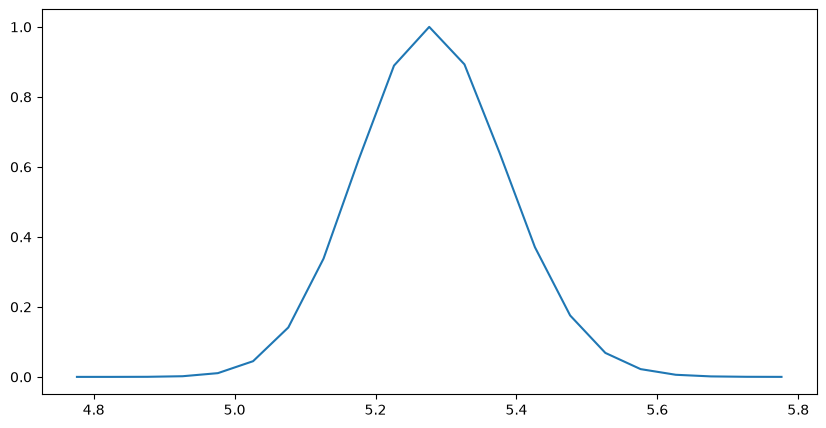

2D Search (Tau) for Part 0: 0it [00:00, ?it/s]

4.926236768936477 is a good enough tau
4.976236768936477 is a good enough tau
5.026236768936477 is a good enough tau
5.076236768936477 is a good enough tau
5.126236768936477 is a good enough tau
5.176236768936477 is a good enough tau
5.226236768936477 is a good enough tau
5.276236768936477 is a good enough tau
5.326236768936477 is a good enough tau
5.376236768936478 is a good enough tau
5.426236768936477 is a good enough tau
5.476236768936477 is a good enough tau
5.526236768936477 is a good enough tau
5.576236768936477 is a good enough tau
5.626236768936478 is a good enough tau
5.676236768936477 is a good enough tau
Part 0 has a 0.0000 probability of bifurcation.
Part 0 has a 0.8489 metastability score.
part 1 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.23
Fitted threshold from parent model: 1.83


Tau grid for part 1:   0%|          | 0/21 [00:00<?, ?it/s]

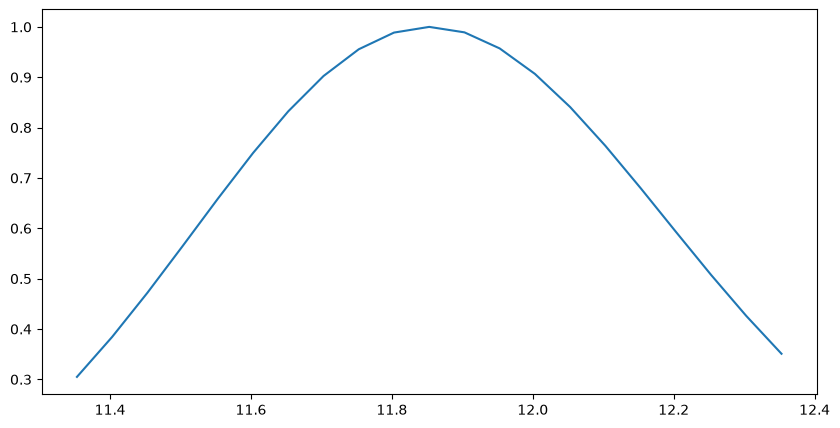

2D Search (Tau) for Part 1: 0it [00:00, ?it/s]

11.35300834990666 is a good enough tau
11.40300834990666 is a good enough tau
11.453008349906659 is a good enough tau
11.50300834990666 is a good enough tau
11.553008349906658 is a good enough tau
11.60300834990666 is a good enough tau
11.65300834990666 is a good enough tau
11.703008349906659 is a good enough tau
11.75300834990666 is a good enough tau
11.803008349906658 is a good enough tau
11.85300834990666 is a good enough tau
11.90300834990666 is a good enough tau
11.953008349906659 is a good enough tau
12.00300834990666 is a good enough tau
12.053008349906658 is a good enough tau
12.10300834990666 is a good enough tau
12.15300834990666 is a good enough tau
12.203008349906659 is a good enough tau
12.25300834990666 is a good enough tau
12.303008349906658 is a good enough tau
12.35300834990666 is a good enough tau
Part 1 has a 0.0000 probability of bifurcation.
Part 1 has a 0.5369 metastability score.
part 2 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.26
Fitted threshold from parent model: 1.58


Tau grid for part 2:   0%|          | 0/21 [00:00<?, ?it/s]

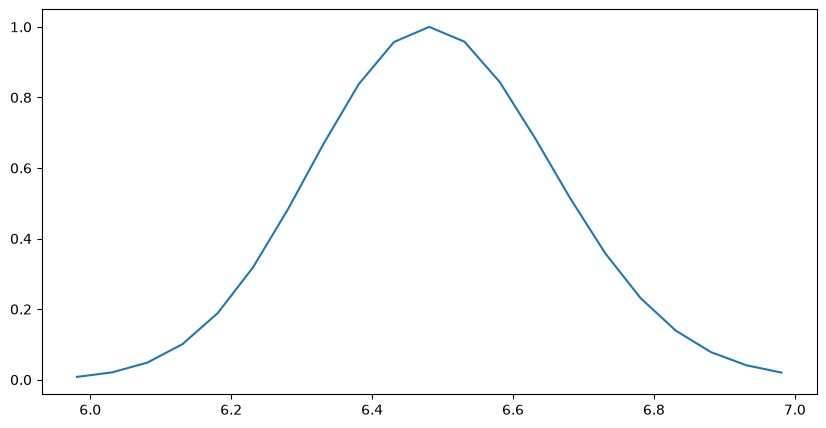

2D Search (Tau) for Part 2: 0it [00:00, ?it/s]

5.981071235991275 is a good enough tau
6.031071235991275 is a good enough tau
6.081071235991275 is a good enough tau
6.131071235991276 is a good enough tau
6.181071235991276 is a good enough tau
6.231071235991275 is a good enough tau
6.281071235991275 is a good enough tau
6.331071235991275 is a good enough tau
6.381071235991276 is a good enough tau
6.431071235991276 is a good enough tau
6.481071235991275 is a good enough tau
6.531071235991275 is a good enough tau
6.581071235991276 is a good enough tau
6.631071235991276 is a good enough tau
6.681071235991276 is a good enough tau
6.731071235991275 is a good enough tau
6.781071235991275 is a good enough tau
6.831071235991276 is a good enough tau
6.881071235991276 is a good enough tau
6.931071235991276 is a good enough tau
6.981071235991275 is a good enough tau
Part 2 has a 0.0000 probability of bifurcation.
Part 2 has a 0.3216 metastability score.
part 3 lets go, best model is Linear, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.24
Fitted threshold from parent model: 2.00


Tau grid for part 3:   0%|          | 0/21 [00:00<?, ?it/s]

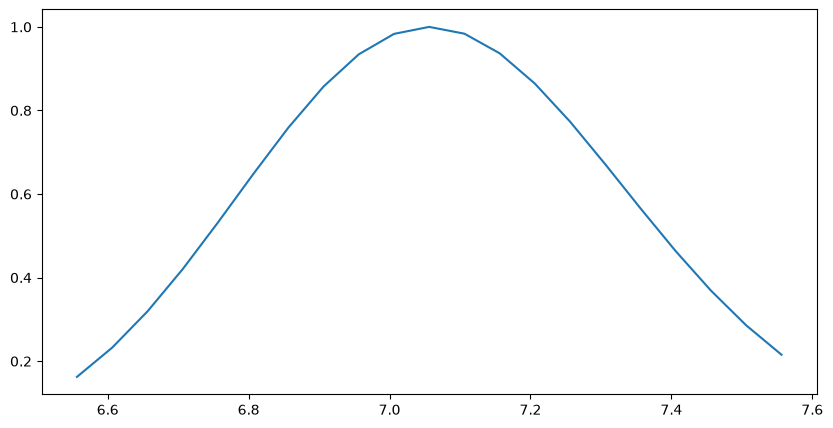

2D Search (Tau) for Part 3: 0it [00:00, ?it/s]

6.556310105046682 is a good enough tau
6.606310105046682 is a good enough tau
6.656310105046682 is a good enough tau
6.706310105046683 is a good enough tau
6.7563101050466825 is a good enough tau
6.806310105046682 is a good enough tau
6.856310105046682 is a good enough tau
6.906310105046682 is a good enough tau
6.956310105046683 is a good enough tau
7.0063101050466825 is a good enough tau
7.056310105046682 is a good enough tau
7.106310105046682 is a good enough tau
7.156310105046682 is a good enough tau
7.206310105046683 is a good enough tau
7.2563101050466825 is a good enough tau
7.306310105046682 is a good enough tau
7.356310105046682 is a good enough tau
7.406310105046682 is a good enough tau
7.456310105046683 is a good enough tau
7.5063101050466825 is a good enough tau
7.556310105046682 is a good enough tau
Part 3 has a 0.0000 probability of bifurcation.
Part 3 has a 0.0000 metastability score.
part 4 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.46
Fitted threshold from parent model: 2.00


Tau grid for part 4:   0%|          | 0/21 [00:00<?, ?it/s]

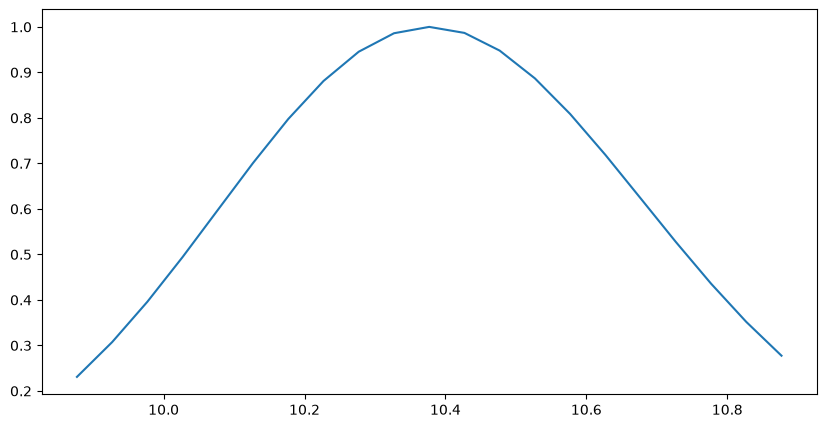

2D Search (Tau) for Part 4: 0it [00:00, ?it/s]

9.877016105450574 is a good enough tau
9.927016105450575 is a good enough tau
9.977016105450573 is a good enough tau
10.027016105450574 is a good enough tau
10.077016105450573 is a good enough tau
10.127016105450574 is a good enough tau
10.177016105450575 is a good enough tau
10.227016105450573 is a good enough tau
10.277016105450574 is a good enough tau
10.327016105450573 is a good enough tau
10.377016105450574 is a good enough tau
10.427016105450575 is a good enough tau
10.477016105450573 is a good enough tau
10.527016105450574 is a good enough tau
10.577016105450573 is a good enough tau
10.627016105450574 is a good enough tau
10.677016105450575 is a good enough tau
10.727016105450573 is a good enough tau
10.777016105450574 is a good enough tau
10.827016105450573 is a good enough tau
10.877016105450574 is a good enough tau
Part 4 has a 0.0000 probability of bifurcation.
Part 4 has a 0.5046 metastability score.
part 5 lets go, best model is NonLinear1, but we'll do ModulatedGain anywa

/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.14
Fitted threshold from parent model: 2.00


Tau grid for part 5:   0%|          | 0/21 [00:00<?, ?it/s]

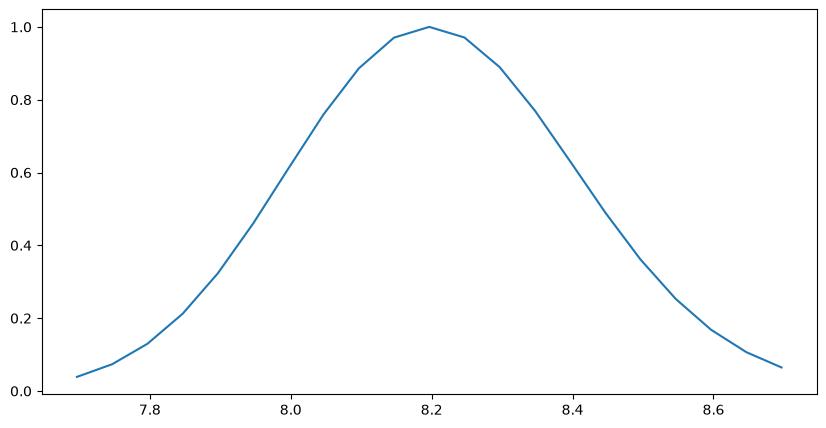

2D Search (Tau) for Part 5: 0it [00:00, ?it/s]

7.696533684766875 is a good enough tau
7.746533684766875 is a good enough tau
7.7965336847668745 is a good enough tau
7.846533684766875 is a good enough tau
7.896533684766875 is a good enough tau
7.946533684766875 is a good enough tau
7.996533684766875 is a good enough tau
8.046533684766874 is a good enough tau
8.096533684766875 is a good enough tau
8.146533684766874 is a good enough tau
8.196533684766875 is a good enough tau
8.246533684766876 is a good enough tau
8.296533684766874 is a good enough tau
8.346533684766875 is a good enough tau
8.396533684766874 is a good enough tau
8.446533684766875 is a good enough tau
8.496533684766876 is a good enough tau
8.546533684766874 is a good enough tau
8.596533684766875 is a good enough tau
8.646533684766874 is a good enough tau
8.696533684766875 is a good enough tau
Part 5 has a 0.0000 probability of bifurcation.
Part 5 has a 0.0000 metastability score.
part 6 lets go, best model is Linear, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.22
Fitted threshold from parent model: 0.00


Tau grid for part 6:   0%|          | 0/21 [00:00<?, ?it/s]

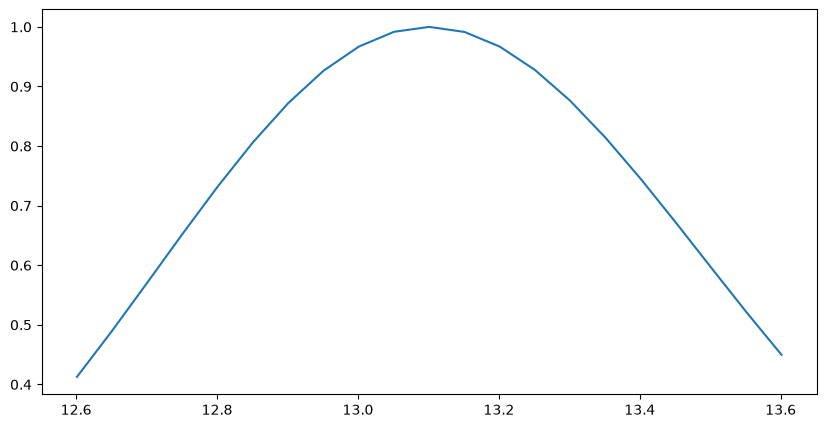

2D Search (Tau) for Part 6: 0it [00:00, ?it/s]

12.601160655057797 is a good enough tau
12.651160655057797 is a good enough tau
12.701160655057796 is a good enough tau
12.751160655057797 is a good enough tau
12.801160655057796 is a good enough tau
12.851160655057797 is a good enough tau
12.901160655057797 is a good enough tau
12.951160655057796 is a good enough tau
13.001160655057797 is a good enough tau
13.051160655057796 is a good enough tau
13.101160655057797 is a good enough tau
13.151160655057797 is a good enough tau
13.201160655057796 is a good enough tau
13.251160655057797 is a good enough tau
13.301160655057796 is a good enough tau
13.351160655057797 is a good enough tau
13.401160655057797 is a good enough tau
13.451160655057796 is a good enough tau
13.501160655057797 is a good enough tau
13.551160655057796 is a good enough tau
13.601160655057797 is a good enough tau
Part 6 has a 0.0000 probability of bifurcation.
Part 6 has a 0.0000 metastability score.
part 7 lets go, best model is NonLinear1, but we'll do ModulatedGain an

/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.23
Fitted threshold from parent model: 2.00


Tau grid for part 7:   0%|          | 0/21 [00:00<?, ?it/s]

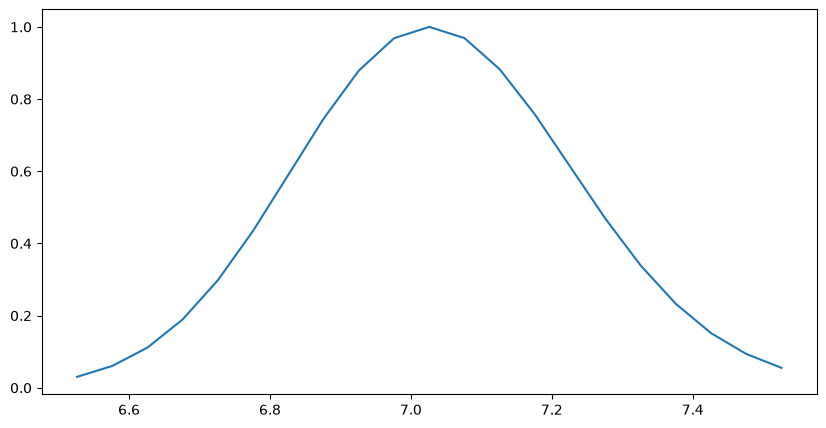

2D Search (Tau) for Part 7: 0it [00:00, ?it/s]

6.526044276711049 is a good enough tau
6.576044276711049 is a good enough tau
6.626044276711049 is a good enough tau
6.67604427671105 is a good enough tau
6.7260442767110495 is a good enough tau
6.776044276711049 is a good enough tau
6.826044276711049 is a good enough tau
6.876044276711049 is a good enough tau
6.92604427671105 is a good enough tau
6.9760442767110495 is a good enough tau
7.026044276711049 is a good enough tau
7.076044276711049 is a good enough tau
7.126044276711049 is a good enough tau
7.17604427671105 is a good enough tau
7.2260442767110495 is a good enough tau
7.276044276711049 is a good enough tau
7.326044276711049 is a good enough tau
7.376044276711049 is a good enough tau
7.42604427671105 is a good enough tau
7.4760442767110495 is a good enough tau
7.526044276711049 is a good enough tau
Part 7 has a 0.0000 probability of bifurcation.
Part 7 has a 0.3450 metastability score.
part 8 lets go, best model is Linear, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.30
Fitted threshold from parent model: 2.00


Tau grid for part 8:   0%|          | 0/21 [00:00<?, ?it/s]

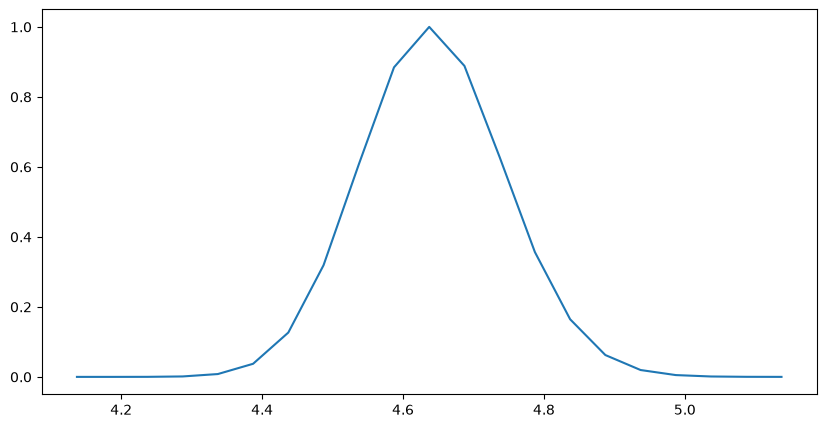

2D Search (Tau) for Part 8: 0it [00:00, ?it/s]

4.287211471386556 is a good enough tau
4.3372114713865555 is a good enough tau
4.387211471386555 is a good enough tau
4.437211471386555 is a good enough tau
4.487211471386555 is a good enough tau
4.537211471386556 is a good enough tau
4.5872114713865555 is a good enough tau
4.637211471386555 is a good enough tau
4.687211471386555 is a good enough tau
4.737211471386555 is a good enough tau
4.787211471386556 is a good enough tau
4.8372114713865555 is a good enough tau
4.887211471386555 is a good enough tau
4.937211471386555 is a good enough tau
4.987211471386555 is a good enough tau
5.037211471386556 is a good enough tau
Part 8 has a 0.0000 probability of bifurcation.
Part 8 has a 0.0000 metastability score.
part 9 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.28
Fitted threshold from parent model: 0.43


Tau grid for part 9:   0%|          | 0/21 [00:00<?, ?it/s]

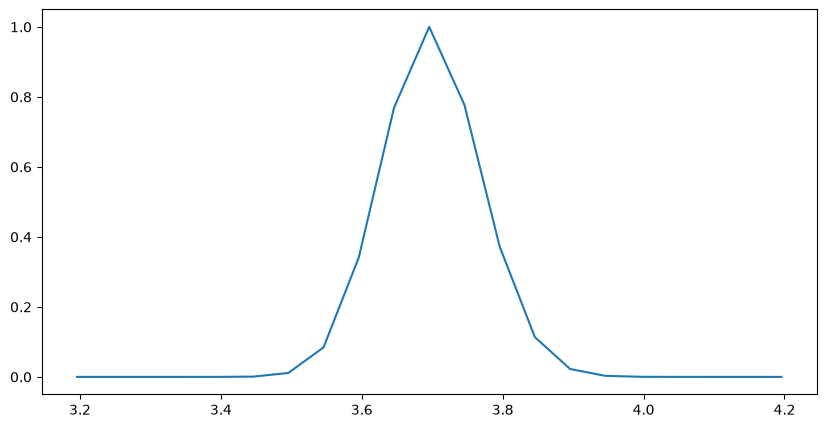

2D Search (Tau) for Part 9: 0it [00:00, ?it/s]

3.4957636293079637 is a good enough tau
3.5457636293079635 is a good enough tau
3.595763629307964 is a good enough tau
3.6457636293079636 is a good enough tau
3.6957636293079634 is a good enough tau
3.7457636293079637 is a good enough tau
3.7957636293079635 is a good enough tau
3.845763629307964 is a good enough tau
3.8957636293079636 is a good enough tau
3.9457636293079634 is a good enough tau
Part 9 has a 0.0000 probability of bifurcation.
Part 9 has a 0.5638 metastability score.
part 10 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.38
Fitted threshold from parent model: 0.35


Tau grid for part 10:   0%|          | 0/21 [00:00<?, ?it/s]

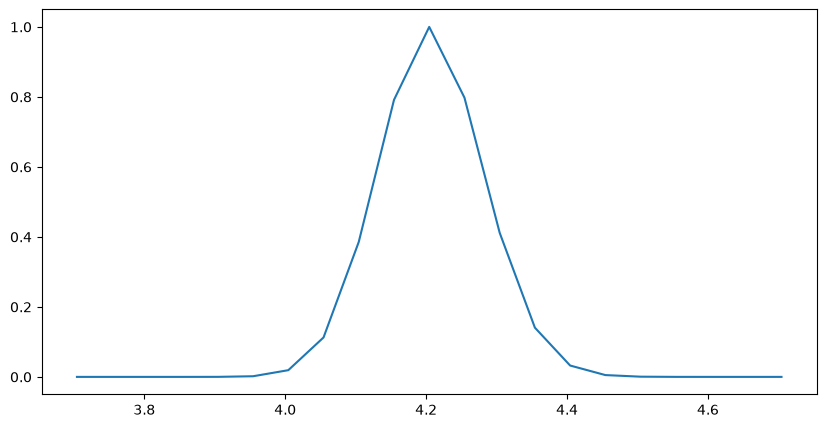

2D Search (Tau) for Part 10: 0it [00:00, ?it/s]

3.95440166108569 is a good enough tau
4.00440166108569 is a good enough tau
4.05440166108569 is a good enough tau
4.10440166108569 is a good enough tau
4.15440166108569 is a good enough tau
4.20440166108569 is a good enough tau
4.25440166108569 is a good enough tau
4.30440166108569 is a good enough tau
4.35440166108569 is a good enough tau
4.40440166108569 is a good enough tau
4.45440166108569 is a good enough tau
Part 10 has a 0.0000 probability of bifurcation.
Part 10 has a 0.9446 metastability score.
part 11 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.32
Fitted threshold from parent model: 2.00


Tau grid for part 11:   0%|          | 0/21 [00:00<?, ?it/s]

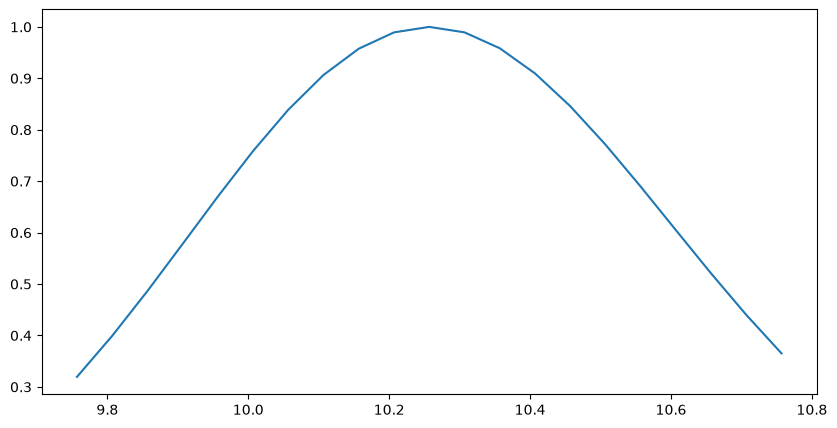

2D Search (Tau) for Part 11: 0it [00:00, ?it/s]

9.75685581239815 is a good enough tau
9.806855812398151 is a good enough tau
9.85685581239815 is a good enough tau
9.90685581239815 is a good enough tau
9.95685581239815 is a good enough tau
10.00685581239815 is a good enough tau
10.056855812398151 is a good enough tau
10.10685581239815 is a good enough tau
10.15685581239815 is a good enough tau
10.20685581239815 is a good enough tau
10.25685581239815 is a good enough tau
10.306855812398151 is a good enough tau
10.35685581239815 is a good enough tau
10.40685581239815 is a good enough tau
10.45685581239815 is a good enough tau
10.50685581239815 is a good enough tau
10.556855812398151 is a good enough tau
10.60685581239815 is a good enough tau
10.65685581239815 is a good enough tau
10.70685581239815 is a good enough tau
10.75685581239815 is a good enough tau
Part 11 has a 0.0000 probability of bifurcation.
Part 11 has a 0.4058 metastability score.
part 12 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.27
Fitted threshold from parent model: 1.97


Tau grid for part 12:   0%|          | 0/21 [00:00<?, ?it/s]

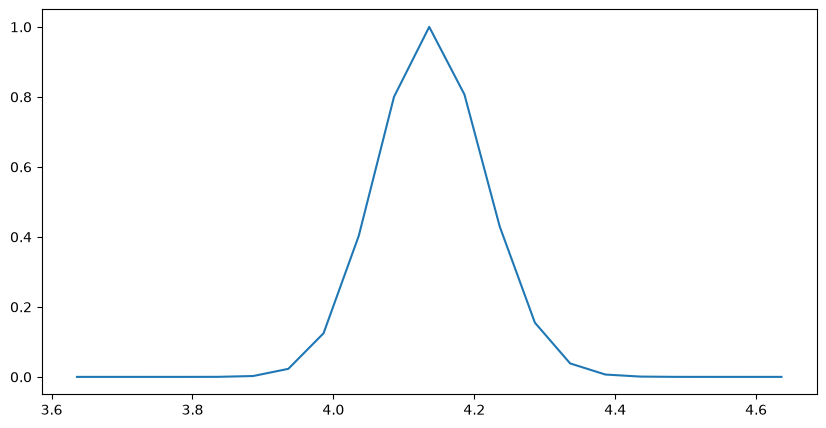

2D Search (Tau) for Part 12: 0it [00:00, ?it/s]

3.886010274333632 is a good enough tau
3.936010274333632 is a good enough tau
3.986010274333632 is a good enough tau
4.036010274333632 is a good enough tau
4.086010274333632 is a good enough tau
4.136010274333632 is a good enough tau
4.186010274333632 is a good enough tau
4.236010274333632 is a good enough tau
4.286010274333632 is a good enough tau
4.336010274333632 is a good enough tau
4.386010274333632 is a good enough tau
Part 12 has a 0.0000 probability of bifurcation.
Part 12 has a 0.7171 metastability score.
part 13 lets go, best model is GainModulation, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.42
Fitted threshold from parent model: 0.50


Tau grid for part 13:   0%|          | 0/21 [00:00<?, ?it/s]

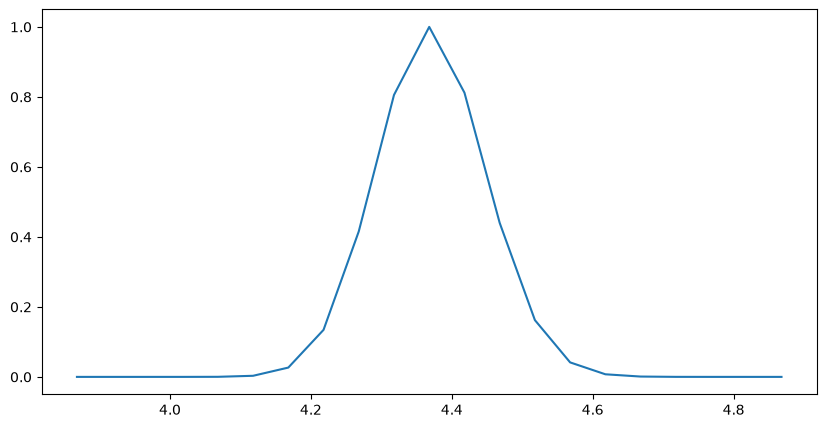

2D Search (Tau) for Part 13: 0it [00:00, ?it/s]

4.117973762657815 is a good enough tau
4.167973762657815 is a good enough tau
4.217973762657815 is a good enough tau
4.267973762657816 is a good enough tau
4.317973762657815 is a good enough tau
4.367973762657815 is a good enough tau
4.417973762657815 is a good enough tau
4.467973762657815 is a good enough tau
4.517973762657816 is a good enough tau
4.567973762657815 is a good enough tau
4.617973762657815 is a good enough tau
Part 13 has a 0.2634 probability of bifurcation.
Part 13 has a 0.9856 metastability score.
part 14 lets go, best model is GainModulation, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.31
Fitted threshold from parent model: 0.48


Tau grid for part 14:   0%|          | 0/21 [00:00<?, ?it/s]

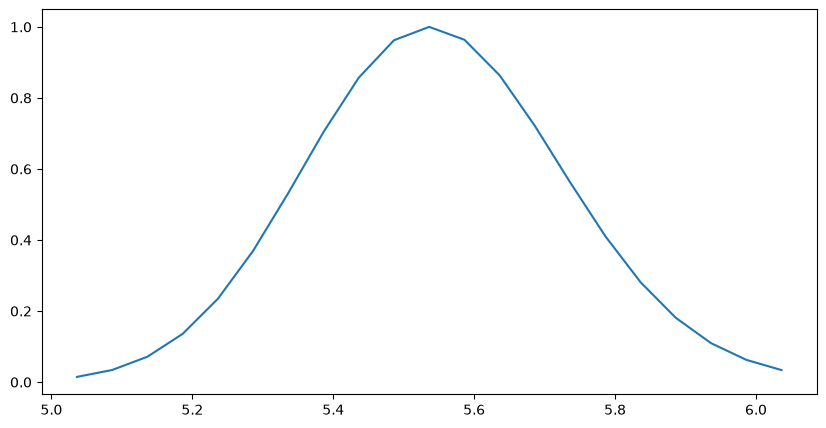

2D Search (Tau) for Part 14: 0it [00:00, ?it/s]

5.03622300878297 is a good enough tau
5.086223008782969 is a good enough tau
5.136223008782969 is a good enough tau
5.18622300878297 is a good enough tau
5.23622300878297 is a good enough tau
5.28622300878297 is a good enough tau
5.336223008782969 is a good enough tau
5.386223008782969 is a good enough tau
5.43622300878297 is a good enough tau
5.48622300878297 is a good enough tau
5.53622300878297 is a good enough tau
5.586223008782969 is a good enough tau
5.63622300878297 is a good enough tau
5.68622300878297 is a good enough tau
5.73622300878297 is a good enough tau
5.78622300878297 is a good enough tau
5.836223008782969 is a good enough tau
5.88622300878297 is a good enough tau
5.93622300878297 is a good enough tau
5.98622300878297 is a good enough tau
6.03622300878297 is a good enough tau
Part 14 has a 0.0000 probability of bifurcation.
Part 14 has a 0.9326 metastability score.
part 15 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.33
Fitted threshold from parent model: 1.38


Tau grid for part 15:   0%|          | 0/21 [00:00<?, ?it/s]

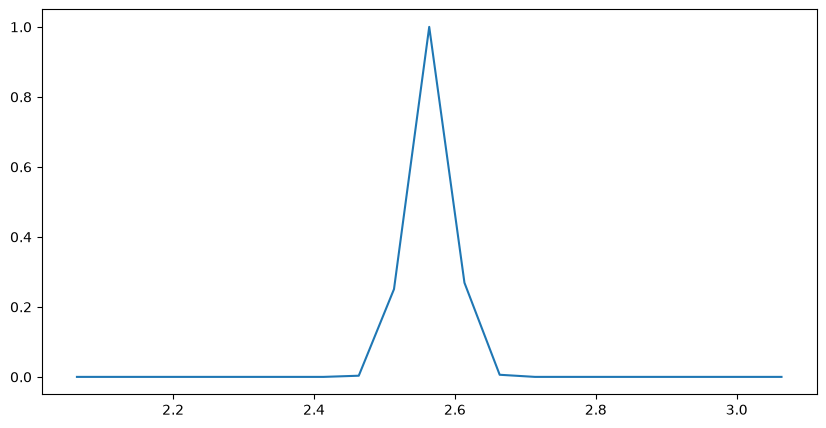

2D Search (Tau) for Part 15: 0it [00:00, ?it/s]

2.46359773780381 is a good enough tau
2.5135977378038104 is a good enough tau
2.56359773780381 is a good enough tau
2.6135977378038104 is a good enough tau
2.6635977378038103 is a good enough tau
Part 15 has a 0.0000 probability of bifurcation.
Part 15 has a 0.4010 metastability score.
part 16 lets go, best model is GainModulation, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.28
Fitted threshold from parent model: 0.33


Tau grid for part 16:   0%|          | 0/21 [00:00<?, ?it/s]

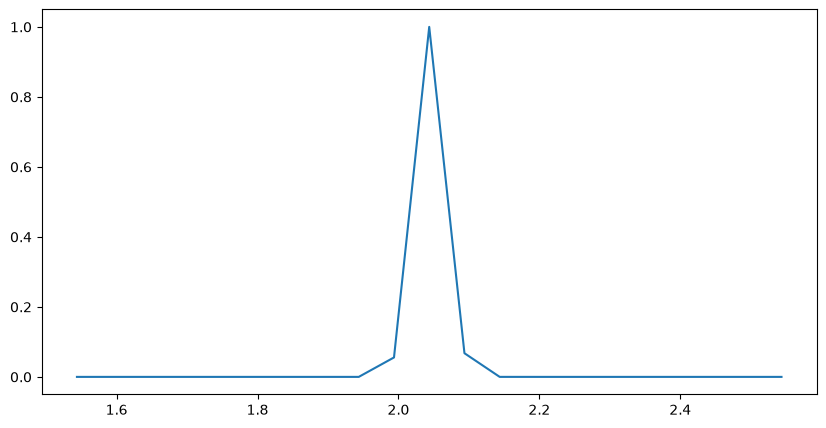

2D Search (Tau) for Part 16: 0it [00:00, ?it/s]

1.9937100845305797 is a good enough tau
2.04371008453058 is a good enough tau
2.0937100845305796 is a good enough tau
Part 16 has a 0.0000 probability of bifurcation.
Part 16 has a 0.8520 metastability score.
part 17 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.25
Fitted threshold from parent model: 0.94


Tau grid for part 17:   0%|          | 0/21 [00:00<?, ?it/s]

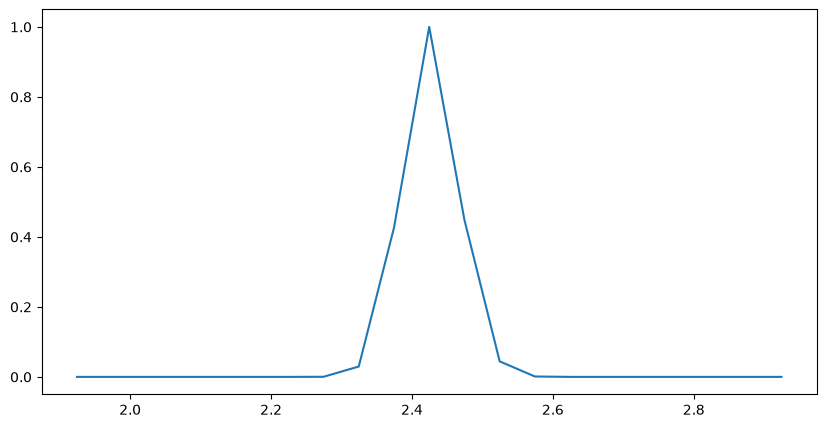

2D Search (Tau) for Part 17: 0it [00:00, ?it/s]

2.3245374795250218 is a good enough tau
2.374537479525022 is a good enough tau
2.424537479525022 is a good enough tau
2.474537479525022 is a good enough tau
2.524537479525022 is a good enough tau
2.5745374795250218 is a good enough tau
Part 17 has a 0.0000 probability of bifurcation.
Part 17 has a 0.6359 metastability score.
part 18 lets go, best model is GainModulation, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.44
Fitted threshold from parent model: 0.42


Tau grid for part 18:   0%|          | 0/21 [00:00<?, ?it/s]

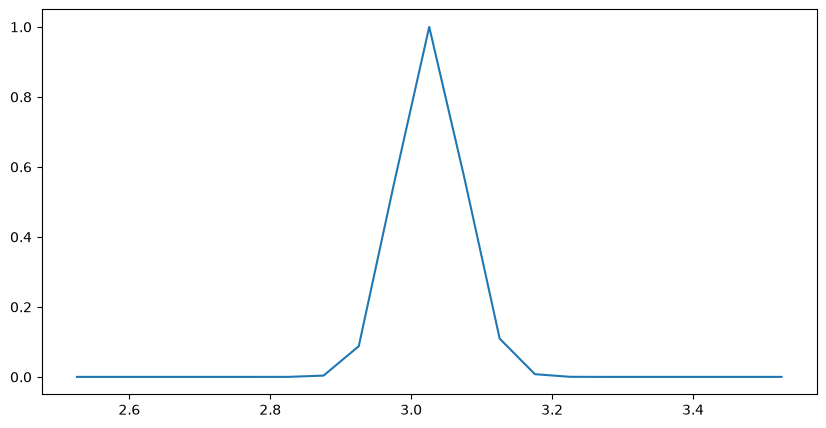

2D Search (Tau) for Part 18: 0it [00:00, ?it/s]

2.8756264111936756 is a good enough tau
2.9256264111936754 is a good enough tau
2.9756264111936757 is a good enough tau
3.0256264111936755 is a good enough tau
3.0756264111936753 is a good enough tau
3.1256264111936756 is a good enough tau
3.1756264111936754 is a good enough tau
Part 18 has a 0.0000 probability of bifurcation.
Part 18 has a 0.9020 metastability score.
part 19 lets go, best model is NonLinear1, but we'll do ModulatedGain anyway


/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/thardy/soundmodelenv/lib/pyt

Max threshold: 1.38
Fitted threshold from parent model: 1.55


Tau grid for part 19:   0%|          | 0/21 [00:00<?, ?it/s]

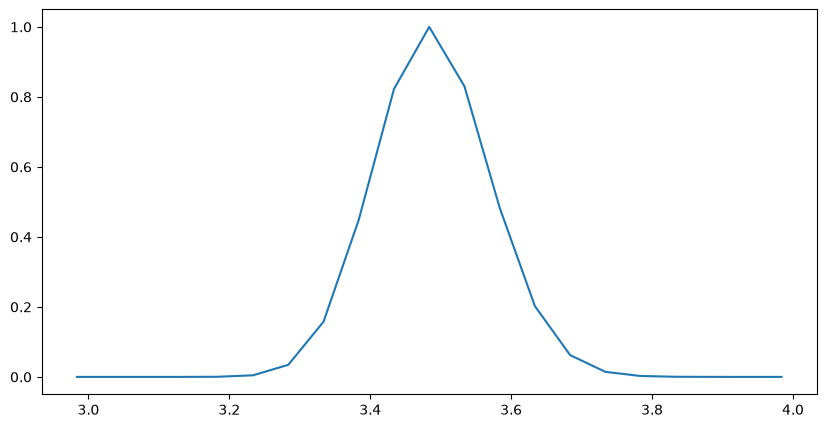

2D Search (Tau) for Part 19: 0it [00:00, ?it/s]

3.2337480883365837 is a good enough tau
3.2837480883365835 is a good enough tau
3.3337480883365838 is a good enough tau
3.3837480883365836 is a good enough tau
3.433748088336584 is a good enough tau
3.4837480883365837 is a good enough tau
3.5337480883365835 is a good enough tau
3.5837480883365838 is a good enough tau
3.6337480883365836 is a good enough tau
3.683748088336584 is a good enough tau
3.7337480883365837 is a good enough tau
3.7837480883365835 is a good enough tau
Part 19 has a 0.0000 probability of bifurcation.
Part 19 has a 0.8185 metastability score.


In [4]:
task = "Passive"
period = "early"
file_path = Path(f'Fit_{task}_{period}')
sub_file_path = "MetaBifurc_ModulatedGain_21^2"

# Define the summary path clearly and load existing progress 
summary_path = file_path / sub_file_path / "metabifurc.csv"
if summary_path.exists():
    print(f"Found existing summary at {summary_path}. Loading progress...")
    existing_df = pd.read_csv(summary_path, index_col=0)
    bifurcation_prob = existing_df["probability_of_bifurcation"].to_dict()
    metastability_scores = existing_df["metastability_score"].to_dict()
    print(bifurcation_prob)
    print(metastability_scores)
else:
    bifurcation_prob, metastability_scores = {}, {}

# load the name of the best model for each participant
json_path = cwd / f"5CV_{task}_{period}.json"
with open(json_path, "r") as f:
    data_5cv = json.load(f)
    results_cv = data_5cv.get("results_cv")
    print("Loaded results_cv:", results_cv)

    
for part in range(20):
    best_model = results_cv[part]
    print(f'part {part} lets go, best model is {best_model}, but we\'ll do ModulatedGain anyway')
    
    # --- SKIP if already processed --- 
    if part in bifurcation_prob:
        print(f">>> Part {part} already exists in CSV. Skipping...")
        continue
    
    # --- Load Data ---
    data_ref = f'myEpochs_{task}/Epoch_{SubIDs[part]}-epo.fif'
    epochs_file = cwd.parents[0] / data_ref
    
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        state_train = lead.STG(epochs_file, tmin=100, tmax=200)
        n_categories = len(list(state_train.keys()))
        categories = list(range(n_categories))

    # --- Input Definition ---
    one_input = np.concatenate((np.zeros(60), np.ones(10), np.zeros(180)))
    input_train = {cat: np.stack([one_input for _ in range(state_train[cat].shape[0])]) for cat in categories}

    # --- Data Reformating ---
    state_train_constant_stim = {cat: state_train[cat][:,60:70] for cat in range(1, n_categories)}
    input_train_constant_stim = {cat: input_train[cat][:,60:70] for cat in range(1, n_categories)}
    no_stim_sliced = np.concatenate([state_train[0][:, i*50:(i+1)*50] for i in range(5)])
    pre_stim_sliced = np.concatenate([state_train[cat][:, :50] for cat in range(1, n_categories)])
    state_train_constant_stim[0] = np.concatenate((no_stim_sliced, pre_stim_sliced))
    input_train_constant_stim[0] = np.zeros_like(state_train_constant_stim[0])

    # --- Define upper bound for threshold parameter ---
    max_threshold = np.percentile(state_train[n_categories-1], 90)
    print(f"Max threshold: {max_threshold:.2f}")

    ########## ONLY MODULATED GAIN ######################
    
    # --- Load Parent Parameters ---
    gainmodul_parent = lead.model.StratifiedGainModulation(
        tau=10, process_noise=0.1, measure_noise=0.1, threshold=1, sharpness=5)
    param_path = file_path / f"GainModulatedModel_part{part}_params"
    gainmodul_parent.load_params(param_path)
    print(f"Fitted threshold from parent model: {gainmodul_parent.threshold:.2f}")


    # --- Define Ranges ---
    thresh_range = np.linspace(0, 2, 21)
    if gainmodul_parent.tau < 2:
        tau_range = np.linspace(1.5, 2.5, 21)
    else:
        tau_range = np.linspace(gainmodul_parent.tau - 0.5, gainmodul_parent.tau + 0.5, 21)

    
    # --- Step 1: Grid Search for Tau (to fix input params for the next step) ---
    
    ll_list_tau, params_through_tau = [], []
    for tau in tqdm(tau_range, desc=f"Tau grid for part {part}"):
        linear_resting_state = lead.model.StratifiedLinear(tau=tau, process_noise=0.1, measure_noise=0.1, w0=0)
        
        linear_resting_state.fit(
            state_series={0: state_train_constant_stim[0]},
            input_series={0: input_train_constant_stim[0]},
            init_params=[tau, 0.1, 0.1] + [0]*7,
            bounds=[(1, 25), (0.01, 1), (0.01, 1)] + [(0, 1)]*7,
            fixed_params=['tau'] + [f'w{i}' for i in range(7)])
        
        ll_list_tau.append(linear_resting_state.loglikelihood({0: state_train_constant_stim[0]}, {0: input_train_constant_stim[0]}))
        params_through_tau.append([linear_resting_state.tau, linear_resting_state.process_noise, linear_resting_state.measure_noise])

    # Plot the distrib for visual check
    ll_array_tau = np.array(ll_list_tau)
    likelihood_tau = np.exp(ll_array_tau - np.max(ll_array_tau))
    plt.figure(figsize=(10,5))
    plt.plot(tau_range, likelihood_tau)
    plt.show()


    # --- Step 2: 2D Grid Search (Tau vs Threshold) ---
    bif_array, meta_array = np.zeros((len(tau_range), len(thresh_range))), np.zeros((len(tau_range), len(thresh_range)))
    ll_array = -np.inf*np.ones((len(tau_range), len(thresh_range)))

    # We iterate through the params found in Step 1
    for idx_tau, [tau, process_noise, measure_noise] in tqdm(enumerate(params_through_tau), desc=f"2D Search (Tau) for Part {part}"):

        # When tau is too unlikely, keep the default ll = -np.inf and bif = meta = 0 (no bifurcation)
        if likelihood_tau[idx_tau] < 0.001:
            continue
        print(f'{tau} is a good enough tau')

        ll_this_tau = ll_list_tau[idx_tau]

        # Inner loop over threshold
        for idx_th, threshold in enumerate(thresh_range):

            # When threshold is too high compared to data, keep the default ll = -np.inf and bif = meta = 0
            if threshold > max_threshold:
                continue
            
            # A. Fit gain and input_weight for this specific (tau, threshold) combo
            ll_local = 0
            # Initialize base model for this grid point
            gainmodul = lead.model.StratifiedGainModulation(
                tau=tau, process_noise=process_noise, measure_noise=measure_noise, 
                threshold=threshold, sharpness=5)
            
            for cat in range(1, n_categories):
                # Retrieve parent weights
                w_parent = getattr(gainmodul_parent, f'w{cat}')
                g_parent = getattr(gainmodul_parent, f'g{cat}')
                
                gainmodul_one_cat = lead.model.GainModulation(
                    tau=tau, process_noise=process_noise, measure_noise=measure_noise, 
                    threshold=threshold, sharpness=5, 
                    input_weight=w_parent, gain=g_parent)
                
                # Fit specific category
                gainmodul_one_cat.fit(
                    state_series={0: state_train_constant_stim[cat]},
                    input_series={0: input_train_constant_stim[cat]},
                    init_params=[getattr(gainmodul_one_cat, pname) for pname in gainmodul_one_cat._param_names],
                    bounds=[(1,25), (0.01, 1), (0.01, 1), (0, 1), (0, 1), (0, 2), (0, 10)],
                    fixed_params=['tau', 'process_noise', 'measure_noise', 'threshold', 'sharpness'])
                
                ll_local += gainmodul_one_cat.loglikelihood({0: state_train_constant_stim[cat]}, {0: input_train_constant_stim[cat]})
                
                # Update the main stratified model with fitted params
                gainmodul.set_params({f'w{cat}': gainmodul_one_cat.input_weight, f'g{cat}': gainmodul_one_cat.gain})
            
            ll_array[idx_tau, idx_th] = ll_this_tau + ll_local
            
            # B. Assess bifurcation and metastability (Linear Interpolation)
            states = np.linspace(-0.5, 3, 1000)
            delta_x_list = []
            max_metascore = 0
            
            for cat in range(n_categories - 1):
                # Initial state diff
                delta_x_list.append(gainmodul.core(state=states, input_value=1, signal_category=cat) - states)
                
                w1, g1 = getattr(gainmodul, f'w{cat}'), getattr(gainmodul, f'g{cat}')
                w2, g2 = getattr(gainmodul, f'w{cat+1}'), getattr(gainmodul, f'g{cat+1}')
                
                # Travel on the (w1, g1) -> (w2, g2) segment 
                for t in np.linspace(0, 1, 100):
                    w, g = w1 + t*(w2-w1), g1 + t*(g2-g1)
                    
                    interp_model = lead.model.GainModulation(
                        tau=tau, process_noise=process_noise, measure_noise=measure_noise, 
                        threshold=threshold, sharpness=5, 
                        input_weight=w, gain=g
                    )

                    # Prepare for metastability score calculation
                    model_func = interp_model.core
                    def f(states, input_value=0, signal_category=cat):
                        return model_func(states, input_value * np.ones_like(states), signal_category) - states
                    def df(states, input_value=0, signal_category=cat):
                        epsilon = 1e-5
                        return (f(states + epsilon, input_value, signal_category) - f(states - epsilon, input_value, signal_category)) / (2*epsilon)
        
                    # Compute metastability score
                    metascore = metastability_score(lambda x: f(x, input_value=1, signal_category=cat), 
                                                    lambda x: df(x, input_value=1, signal_category=cat), 
                                                    states, tau=tau)
                    max_metascore = max(max_metascore, metascore)

                    # Prepare for bifurcation check
                    delta_x_list.append(interp_model.core(state=states, input_value=1, signal_category=0) - states)

            # Compute bifurcation check
            bifbool = is_bifurcation(delta_x_list)
            bif_array[idx_tau, idx_th] = int(bifbool)
            meta_array[idx_tau, idx_th] = max_metascore

    ########## ONLY MODULATED GAIN ######################


    if best_model == 'Linear':
        bif_array, meta_array = np.zeros((20, 20)), np.zeros((20, 20))
        ll_array = -np.ones((20, 20))


    # --- Process Results ---
    likelihood = np.exp(ll_array - np.max(ll_array))

    # Save Results
    os.makedirs(file_path / sub_file_path, exist_ok=True)
    np.savez(file_path / sub_file_path / f"2D_grid_search_part{part}.npz", threshold_range=thresh_range, tau_range=tau_range, ll=ll_array, likelihood=likelihood, bifbool=bif_array, metascore=meta_array)

    # Weighting BifProb and MetaScore over the 2D surface)
    bifprob = np.average(bif_array, weights=likelihood)
    metascore = np.average(meta_array, weights=likelihood)
    bifurcation_prob[part], metastability_scores[part] = bifprob, metascore
    print(f'Part {part} has a {bifprob:.4f} probability of bifurcation.')
    print(f'Part {part} has a {metascore:.4f} metastability score.')

    # Save summary CSV
    df_bifprob = pd.DataFrame.from_dict(
        bifurcation_prob, orient="index", columns=["probability_of_bifurcation"]
    ).sort_index()
    df_metascore = pd.DataFrame.from_dict(
        metastability_scores, orient="index", columns=["metastability_score"]
    ).sort_index()
    df = pd.concat([df_bifprob, df_metascore], axis=1)
    df.to_csv(file_path / sub_file_path / "metabifurc.csv")

    # --- 3. Plotting (2D Heatmap with Contours) ---
    plt.figure(figsize=(10, 8))
    
    # Create 2D Meshgrid for plotting
    # thresh_range (x-axis), tau_range (y-axis)
    X, Y = np.meshgrid(thresh_range, tau_range)
    
    # 1. Plot Heatmap of Likelihood
    # Using pcolormesh for the heatmap
    pcm = plt.pcolormesh(X, Y, likelihood, shading='auto', cmap='viridis')
    plt.colorbar(pcm, label='Relative Likelihood')
    
    # 2. Plot Contour of Bifurcation Boundary
    # We draw a line at 0.5 (since bif_array is 0 or 1) to show the border
    # colors='red' makes the bifurcation line distinct
    if np.any(bif_array) and not np.all(bif_array):
        CS = plt.contour(X, Y, bif_array, levels=[0.5], colors='red', linewidths=2)
        # Create a proxy artist for the legend
        from matplotlib.lines import Line2D
        proxy_line = Line2D([0], [0], color='red', linewidth=2, label='Bifurcation Boundary')
        plt.legend(handles=[proxy_line], loc='upper right')
    elif np.all(bif_array):
        plt.title(f"Part {part} (All Bifurcation)")
    else:
        plt.title(f"Part {part} (No Bifurcation)")

    plt.title(f'Parameter Space: Tau vs Threshold - Part {part}\nWeighted Bifurcation Prob: {bifprob:.3f}')
    plt.xlabel('Threshold')
    plt.ylabel('Tau')
    
    # Save plot
    plt.savefig(file_path / sub_file_path / f"2D_likelihood_part{part}_{task}.png")
    plt.close()